# Retraction Contamination Tracker: demo

**The problem.** When a scientific paper is retracted (withdrawn, for example because its data was fabricated),
the papers that cited it don't disappear. Some keep citing it for years. This notebook uses our graph of
**453 retracted dentistry papers** and the **8,881 papers that cite them** to show how far that goes.

**How to read it.** Each section answers one question, in the same order:
the question, a chart, then **one sentence with the answer**, computed from the data. You don't need to read the
code to follow it: the grey cells only fetch the data and draw the charts.

| Word | Meaning here |
| --- | --- |
| **Retracted paper** | A paper that Retraction Watch lists as withdrawn |
| **Zombie citation** | A citation made **after** the cited paper was retracted |
| **PageRank** | A score that is high when many papers, and important ones, build on a paper |
| **Community** | A group of papers that cite each other much more than the rest (found by the Louvain algorithm) |

Being linked to a retracted paper means being **exposed** to it, not being wrong: a paper can cite a retracted one
only to mention or criticise it.

<details><summary><b>To run this notebook yourself</b> (click)</summary>

```bash
make install                               # Python packages, including the ones for this notebook
make docker-run                            # Neo4j, the API and Nginx
.venv/bin/python -m scripts.ingest         # the real data
.venv/bin/python -m scripts.load_sample    # 20 hand-written papers, used in section 6
.venv/bin/jupyter notebook demo.ipynb      # then "Run All Cells"
```

Section 7 (AI) also needs a Gemini key in `.env`, and the Risk cell a trained model
(`.venv/bin/python -m app.services.risk`). Without them, those cells say so instead of failing.
</details>

### Setup
Connects to Neo4j (to read the graph directly) and to the API (like a real user would, through Nginx).

In [1]:
import re
import textwrap
import warnings

import httpx
import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd
from matplotlib.patches import Patch

from app.config import get_settings
from app.database import Neo4jClient

API = "http://localhost"
RED, ORANGE, BLUE, GREY = "#c43a3a", "#e07b39", "#3a66c4", "#cccccc"
warnings.filterwarnings("ignore", message="Glyph .* missing from font")  # titles in other alphabets
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

db = Neo4jClient.from_settings(get_settings())
assert db.is_available(), "Neo4j is not reachable: run `make docker-run` first"


def query(cypher: str, **params) -> pd.DataFrame:
    """Run a read-only Cypher query and return the rows as a table."""
    return pd.DataFrame(db.read(cypher, params))


def get(path: str, **params) -> dict:
    """Call one of our API endpoints and return its JSON answer."""
    response = httpx.get(API + path, params=params, timeout=120)
    response.raise_for_status()
    return response.json()


def clean(title: str) -> str:
    """Remove the 'RETRACTED ARTICLE:' kind of prefix that some titles carry."""
    return re.sub(r"^\W*retracted( article)?\W*", "", str(title), flags=re.IGNORECASE).strip()


def short(text: str, width: int = 45) -> str:
    """Wrap a long title on two lines at most, so chart labels stay readable."""
    return "\n".join(textwrap.wrap(clean(text), width)[:2])


def readable(titles: list[str], fallback: str) -> str:
    """The first title written in Latin letters (the chart font has no Chinese or Japanese), or a fallback."""
    for title in titles or []:
        if title and sum(ch.isascii() for ch in title) / len(title) > 0.9:
            return short(title, 50)
    return fallback


print("API:", get("/health/ready"))

API: {'status': 'ok', 'version': '0.1.0', 'neo4j': 'up'}


## 1. What is in the graph?

Every circle in the graph is a *node* (a paper, an author, a journal...) and every arrow a *relationship*
(a citation, an authorship...). Sections 1 to 5 count the **real data only**: the 20 hand-written sample
papers, used in section 6, are left out, so the numbers match the README.

In [2]:
# "sample IS NULL" keeps the real data: every node of the hand-written sample graph has sample = true
counts = query("""
    RETURN COUNT { (p:Paper) WHERE p.sample IS NULL } AS papers,
           COUNT { (p:Paper:Retracted) WHERE p.sample IS NULL } AS retracted,
           COUNT { (a:Paper)-[:CITES]->(b:Paper) WHERE a.sample IS NULL AND b.sample IS NULL } AS citations,
           COUNT { (a:Paper)-[c:CITES]->(r:Paper:Retracted)
                   WHERE c.before_retraction = false AND a.sample IS NULL AND r.sample IS NULL } AS zombies,
           COUNT { (a:Author) WHERE a.sample IS NULL } AS authors,
           COUNT { (j:Journal) WHERE j.sample IS NULL } AS journals,
           COUNT { (r:Reason) WHERE EXISTS { (r)<-[:FOR_REASON]-(n:RetractionNotice) WHERE n.sample IS NULL } } AS reasons
""").iloc[0]

pd.DataFrame(
    [
        ("Papers", counts.papers, "retracted papers and the papers that cite them"),
        ("of which retracted", counts.retracted, "listed as withdrawn by Retraction Watch"),
        ("Citations", counts.citations, "'paper A cites paper B' links"),
        ("of which zombie citations", counts.zombies, "made after the cited paper was retracted"),
        ("Authors", counts.authors, "identified by their OpenAlex id, not their name"),
        ("Journals", counts.journals, "where the papers were published"),
        ("Retraction reasons", counts.reasons, "e.g. 'Paper Mill', 'Concerns/Issues about Data'"),
    ],
    columns=["What", "How many", "Meaning"],
).style.hide(axis="index").format({"How many": "{:,}"})

What,How many,Meaning
Papers,"9,334",retracted papers and the papers that cite them
of which retracted,453,listed as withdrawn by Retraction Watch
Citations,"10,139",'paper A cites paper B' links
of which zombie citations,"4,861",made after the cited paper was retracted
Authors,"31,191","identified by their OpenAlex id, not their name"
Journals,"2,402",where the papers were published
Retraction reasons,73,"e.g. 'Paper Mill', 'Concerns/Issues about Data'"


## 2. When, and why, were these papers retracted?

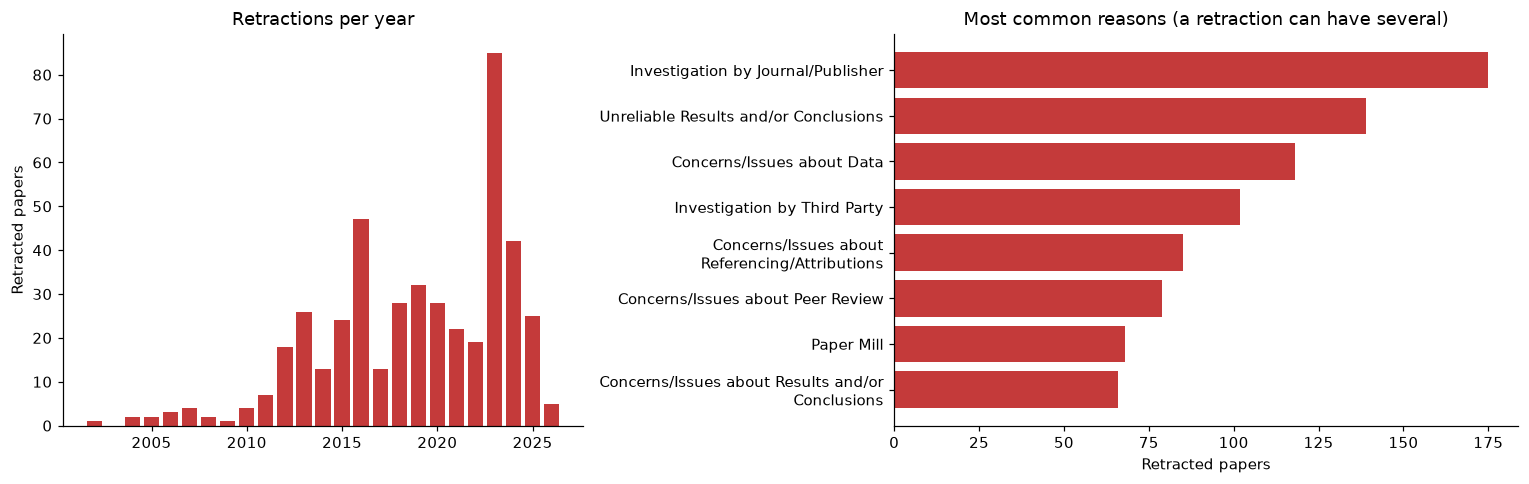

Answer: retractions grew over time and peaked in 2023 (85 papers). The most common reason is 'Investigation by Journal/Publisher' (175 papers).


In [3]:
per_year = query("""
    MATCH (n:RetractionNotice {source: 'Retraction Watch'})-[:RETRACTS]->(:Paper)
    WHERE n.date IS NOT NULL AND n.sample IS NULL
    RETURN n.date.year AS year, count(*) AS retractions ORDER BY year
""")
reasons = query("""
    MATCH (n:RetractionNotice {source: 'Retraction Watch'})-[:FOR_REASON]->(r:Reason)
    WHERE n.sample IS NULL
    RETURN r.name AS reason, count(*) AS retractions ORDER BY retractions DESC LIMIT 8
""")

fig, (left, right) = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [1, 1.2]})
left.bar(per_year["year"], per_year["retractions"], color=RED)
left.set_title("Retractions per year")
left.set_ylabel("Retracted papers")
right.barh([short(r, 40) for r in reasons["reason"]], reasons["retractions"], color=RED)
right.invert_yaxis()
right.set_title("Most common reasons (a retraction can have several)")
right.set_xlabel("Retracted papers")
plt.tight_layout()
plt.show()

peak = per_year.loc[per_year["retractions"].idxmax()]
print(f"Answer: retractions grew over time and peaked in {peak.year} ({peak.retractions} papers). "
      f"The most common reason is '{reasons.reason[0]}' ({reasons.retractions[0]} papers).")

## 3. Do papers keep citing retracted work?

Every citation to a retracted paper has a flag, `before_retraction`, computed once when the data is loaded.
A citation is only counted as a **zombie** when we are sure it came after the retraction.

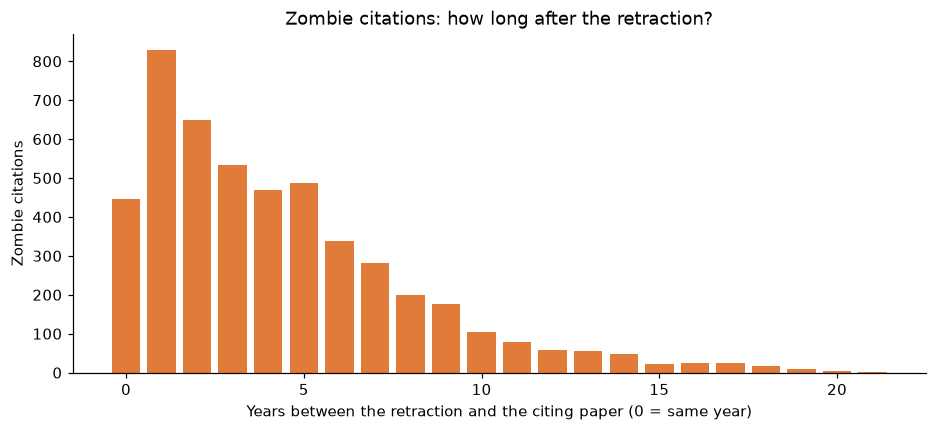

Answer: yes. 4,861 of the 10,139 citations to retracted papers (48%) were made after the retraction, and 1,932 of them 5 years or more after it.


In [4]:
delay = query("""
    MATCH (citing:Paper)-[c:CITES]->(:Paper:Retracted)<-[:RETRACTS]-(n:RetractionNotice {source: 'Retraction Watch'})
    WHERE c.before_retraction = false AND citing.year IS NOT NULL AND n.date IS NOT NULL
      AND citing.sample IS NULL AND n.sample IS NULL
    RETURN citing.year - n.date.year AS years_after, count(*) AS citations ORDER BY years_after
""")
total = int(counts.zombies + query("""
    MATCH (a:Paper)-[c:CITES]->(r:Paper:Retracted)
    WHERE c.before_retraction = true AND a.sample IS NULL AND r.sample IS NULL
    RETURN count(c) AS n
""").n[0])

plt.figure(figsize=(10, 4))
plt.bar(delay["years_after"], delay["citations"], color=ORANGE)
plt.xlabel("Years between the retraction and the citing paper (0 = same year)")
plt.ylabel("Zombie citations")
plt.title("Zombie citations: how long after the retraction?")
plt.show()

later = delay[delay["years_after"] >= 5]["citations"].sum()
print(f"Answer: yes. {counts.zombies:,} of the {total:,} citations to retracted papers "
      f"({counts.zombies / total:.0%}) were made after the retraction, "
      f"and {later:,} of them 5 years or more after it.")

### Which journals publish them?

This is our **Zombie citations** endpoint (`GET /api/journals/zombie-citations`). Orange: citations made after the
retraction. Grey: citations made before it. (OpenAlex sometimes lists a book series or a database instead of a
journal, for example *Springer eBooks*.)

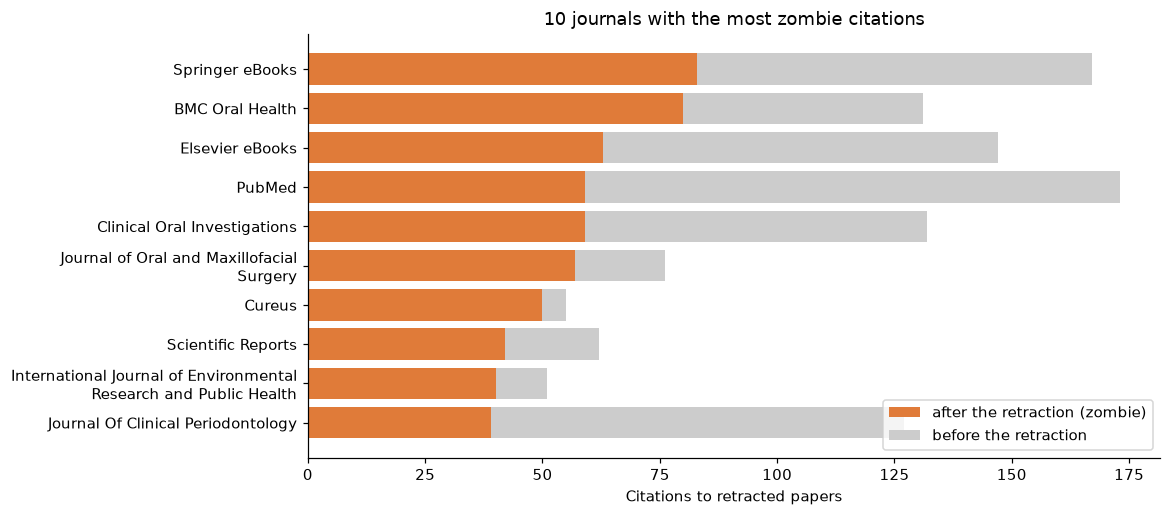

Answer: 'Springer eBooks' comes first, with 83 zombie citations (50% of its citations to retracted papers).


In [5]:
zombies = pd.DataFrame(get("/api/journals/zombie-citations", limit=10)["items"])
plt.figure(figsize=(10, 5))
names = [short(j, 40) for j in zombies["journal"]]
plt.barh(names, zombies["zombie_citations"], color=ORANGE, label="after the retraction (zombie)")
plt.barh(names, zombies["citations_to_retracted"] - zombies["zombie_citations"],
         left=zombies["zombie_citations"], color=GREY, label="before the retraction")
plt.gca().invert_yaxis()
plt.xlabel("Citations to retracted papers")
plt.legend(loc="lower right")
plt.title("10 journals with the most zombie citations")
plt.show()

top = zombies.iloc[0]
print(f"Answer: '{top.journal}' comes first, with {top.zombie_citations} zombie citations "
      f"({top.zombie_share:.0%} of its citations to retracted papers).")

### A real example: one paper, retracted in 2007, still cited every year

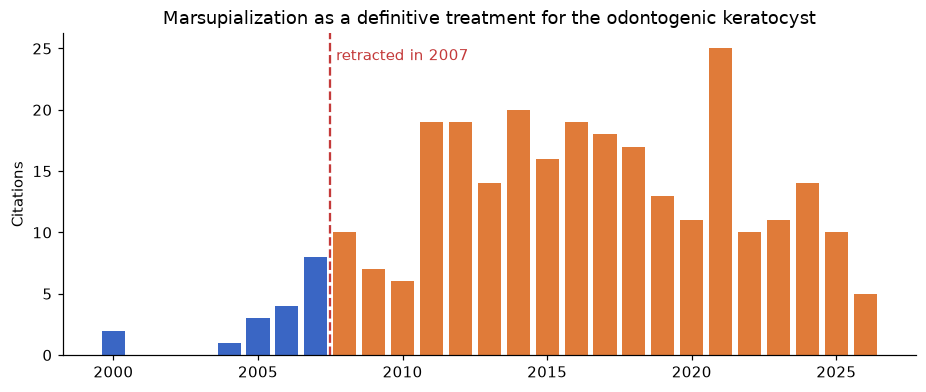

Answer: 'Marsupialization as a definitive treatment for the odontogenic keratocyst' (2004) was retracted in 2007, and was still cited 268 times afterwards.


In [6]:
paper = query("""
    MATCH (r:Paper:Retracted)<-[c:CITES]-(:Paper)
    WHERE c.before_retraction = false
    WITH r, count(c) AS zombies ORDER BY zombies DESC LIMIT 1
    MATCH (n:RetractionNotice {source: 'Retraction Watch'})-[:RETRACTS]->(r)
    RETURN r.doi AS doi, r.title AS title, r.year AS year, n.date.year AS retracted, zombies
""").iloc[0]
citations = query("""
    MATCH (c:Paper)-[:CITES]->(:Paper {doi: $doi}) WHERE c.year IS NOT NULL
    RETURN c.year AS year, count(*) AS citations ORDER BY year
""", doi=paper.doi)

plt.figure(figsize=(10, 3.8))
colours = [ORANGE if y > paper.retracted else BLUE for y in citations["year"]]
plt.bar(citations["year"], citations["citations"], color=colours)
plt.axvline(paper.retracted + 0.5, color=RED, linestyle="--")
plt.text(paper.retracted + 0.7, citations["citations"].max(), f"retracted in {paper.retracted}", color=RED, va="top")
plt.ylabel("Citations")
plt.title(short(paper.title, 80))
plt.show()
print(f"Answer: '{paper.title}' ({paper.year}) was retracted in {paper.retracted}, "
      f"and was still cited {paper.zombies} times afterwards.")

## 4. Which retracted papers did the most damage?

Counting citations is not enough: a paper cited by papers that are themselves widely cited spreads further.
**PageRank** captures that. This is our **Top spreaders** endpoint, which runs PageRank (Neo4j Graph Data
Science) on the whole citation graph and keeps the retracted papers. (In the chart, the "RETRACTED:" prefix that some titles
carry is removed to keep the labels short.)

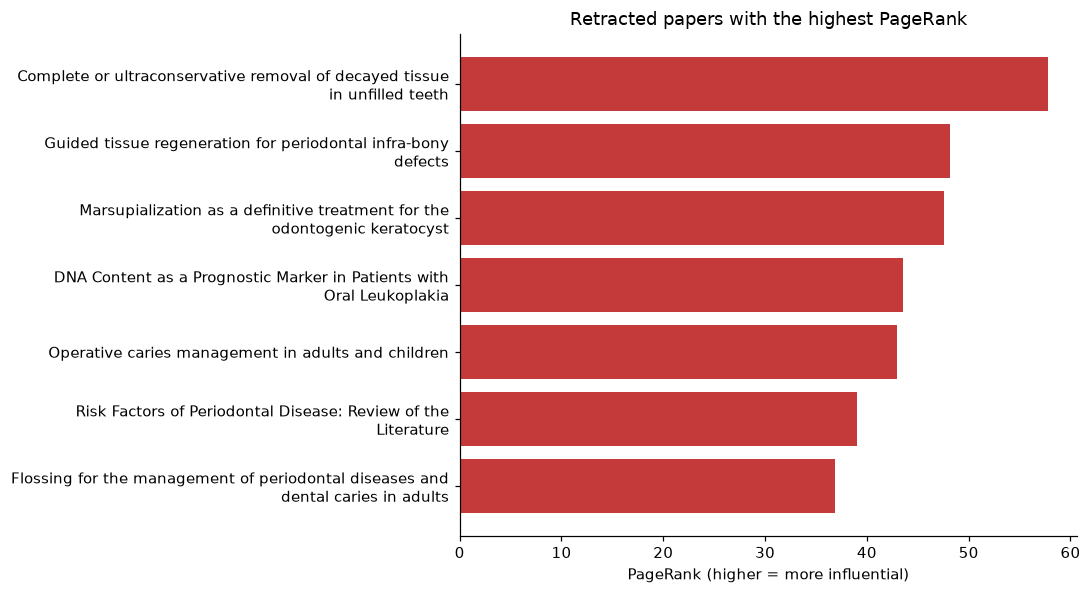

title,year,pagerank,direct_citations,citations_after_retraction
Complete or ultraconservative removal of decayed tissue in unfilled teeth,2006,57.751700,197,30
Guided tissue regeneration for periodontal infra-bony defects,2006,48.202300,373,118
Marsupialization as a definitive treatment for the odontogenic keratocyst,2004,47.543900,282,268
Guided tissue regeneration for periodontal infra-bony defects,1999,43.990700,37,18
RETRACTED: DNA Content as a Prognostic Marker in Patients with Oral Leukoplakia,2001,43.532700,285,95
Operative caries management in adults and children,2013,42.914600,364,168
Risk Factors of Periodontal Disease: Review of the Literature,2014,39.037500,308,112
Flossing for the management of periodontal diseases and dental caries in adults,2011,36.828700,219,91


In [7]:
spreaders = pd.DataFrame(get("/api/retractions/top-spreaders", limit=8)["items"])
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.barh([short(t, 55) for t in spreaders["title"]], spreaders["pagerank"], color=RED)
ax.invert_yaxis()
ax.set_xlabel("PageRank (higher = more influential)")
ax.set_title("Retracted papers with the highest PageRank")
plt.tight_layout()
plt.show()
spreaders[["title", "year", "pagerank", "direct_citations", "citations_after_retraction"]].style.hide(axis="index")

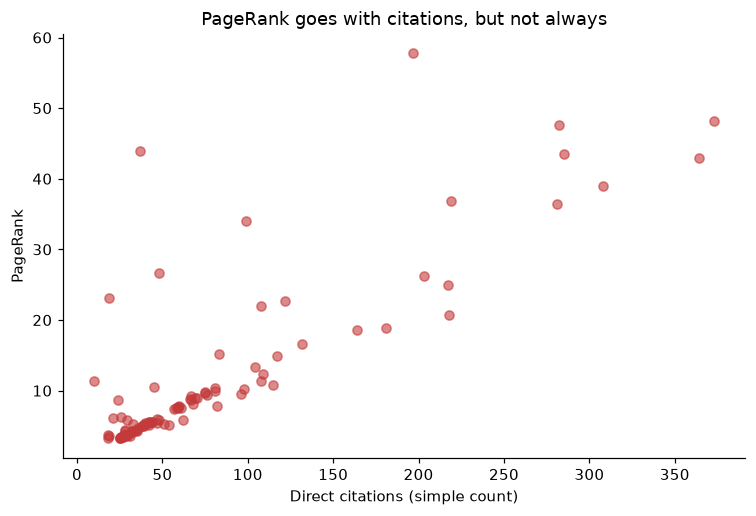

Answer: the most cited papers usually have a high PageRank, but some papers with few citations score high because the papers citing them are themselves central (the points far above the trend).


In [8]:
everything = pd.DataFrame(get("/api/retractions/top-spreaders", limit=100)["items"])
plt.figure(figsize=(8, 5))
plt.scatter(everything["direct_citations"], everything["pagerank"], alpha=0.6, color=RED)
plt.xlabel("Direct citations (simple count)")
plt.ylabel("PageRank")
plt.title("PageRank goes with citations, but not always")
plt.show()
print("Answer: the most cited papers usually have a high PageRank, but some papers with few citations score high "
      "because the papers citing them are themselves central (the points far above the trend).")

## 5. Which research areas are the most contaminated?

**Louvain** groups papers that cite each other a lot: each group is roughly a research topic. Our
**Communities** endpoint ranks the groups by their share of retracted papers. Each group is named here by one of
its papers' titles. Groups under 20 papers are hidden, otherwise a group of 3 papers with 1 retraction would come
first.

*About the labels:* we pick a title written in Latin letters (the chart font cannot draw Chinese or Japanese
titles, and some papers have them), and we remove the "RETRACTED ARTICLE:" prefix that some titles carry. This only
changes the chart labels, not the data: the table below the chart keeps the original titles.

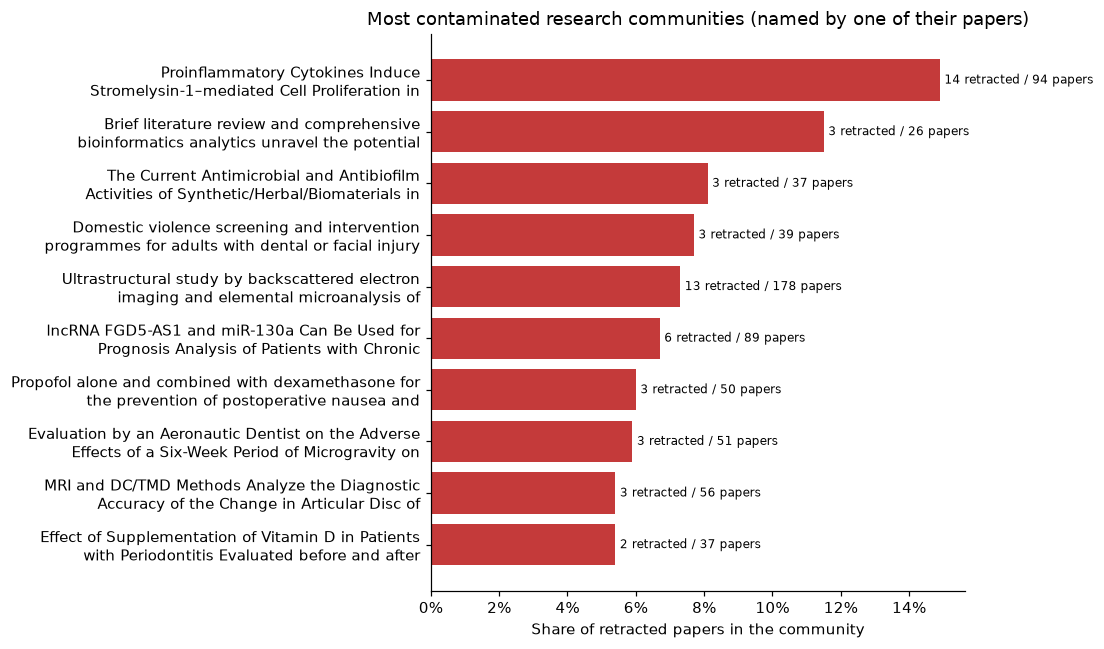

Answer: in the most contaminated community, 15% of the papers are retracted (14 of 94).


community_id,size,retracted_papers,retracted_share,sample_titles
206,94,14,0.149000,"['論文撤回：炎症性サイトカイン誘導MMP-3はマウスiPS細胞由来象牙芽細胞の増殖を制御する', '幹細胞由来高純度象牙芽細胞を用いた in vitro 歯髄炎モデルにおけるMMP-3の新規知見', 'RETRACTED: Proinflammatory Cytokines Induce Stromelysin-1–mediated Cell Proliferation in Dental Pulp Fibroblast-like Cells']"
1,26,3,0.115000,"['RETRACTED ARTICLE: Brief literature review and comprehensive bioinformatics analytics unravel the potential mechanism of curcumin in the treatment of periodontitis', 'Observation on the Effect of Bone Grafting Alone and Guided Tissue Regeneration Combined with Bone Grafting to Repair Periodontal Intraosseous Defects', 'Enamel Matrix Derivatives for Periodontal Regeneration: Recent Developments and Future Perspectives']"
49,37,3,0.081000,"['[Retracted] The Current Antimicrobial and Antibiofilm Activities of Synthetic/Herbal/Biomaterials in Dental Application', 'RETRACTED: Comparative evaluation of Sapindus Mukorossi extract with 17% EDTA on smear layer removal in various parts of the tooth root', 'Comparison of Short-Term Restorative Effects and Periodontal Health Status of Restorations Made of Different Materials in Full-Crown Restoration of Mandibular Premolar Tooth Defects']"
184,39,3,0.077000,"['Domestic violence screening and intervention programmes for adults with dental or facial injury', 'Domestic violence screening and intervention programmes for adults with dental or facial injury', 'Treatments for adults with prominent lower front teeth']"
95,178,13,0.073000,"['RETRACTED: Ultrastructural study by backscattered electron imaging and elemental microanalysis of biomaterial‐to‐bone interface and mineral degradation of bovine xenografts in maxillary sinus floor elevation', 'RETRACTED: Ultrastructural study by backscattered electron imaging and elemental microanalysis of bone‐to‐biomaterial interface and mineral degradation of porcine xenografts used in maxillary sinus floor elevation', 'RETRACTED: Biphasic β‐TCP mixed with silicon increases bone formation in critical site defects in rabbit calvaria']"
23,89,6,0.067000,"['[Retracted] lncRNA FGD5‐AS1 and miR‐130a Can Be Used for Prognosis Analysis of Patients with Chronic Periodontitis', '[Retracted] The Expression of miR‐23a and miR‐146a in the Saliva of Patients with Periodontitis and Its Clinical Significance', 'RETRACTED ARTICLE: Identification and assessment of differentially expressed necroptosis long non-coding RNAs associated with periodontitis in human']"
228,50,3,0.060000,"['RETRACTED: Propofol alone and combined with dexamethasone for the prevention of postoperative nausea and vomiting in adult Japanese patients having third molars extracted', 'RETRACTED: Reduction of postoperative emetic episodes and analgesic requirements with dexamethasone in patients scheduled for dental surgery', 'RETRACTED ARTICLE: Prevention of nausea and vomiting after dental surgery: a comparison of small doses of propofol, droperidol, and metoclopramide']"
181,51,3,0.059000,"['Evaluation by an Aeronautic Dentist on the Adverse Effects of a Six-Week Period of Microgravity on the Oral Cavity', 'Association Between Stress, Sleep Quality and Temporomandibular Joint Dysfunction: Simulated Mars Mission', 'RETRACTED ARTICLE: Aeronautic dentistry: an upcoming branch']"
64,56,3,0.054000,"['MRI and DC/TMD Methods Analyze the Diagnostic Accuracy of the Change in Articular Disc of Temporomandibular Joint', 'Clinical Manifestations, Imaging Features, and Pathogenic/Prognostic Risk Factors for Temporomandibular Disorders (TMD): A Case-Control Study Based on Psychogenic Factors of Patients', 'RETRACTED: Temporomandibular disorders in relation to female reproductive hormones: A literature review']"
88,37,2,0.054000,"['[Retracted] Effect of Supplementation of Vitamin D in Patients with Periodontitis Evaluated before and after Nonsurgical Therapy', 'Anti-inflammatory effect of vitamin D on gingivitis: A dose response randomised controlled trial', 'Vitamin D and Its Role in Oral D

In [9]:
communities = pd.DataFrame(get("/api/communities", limit=10, min_size=20)["items"])
labels = [readable(titles, f"community {cid}")
          for titles, cid in zip(communities["sample_titles"], communities["community_id"])]
fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(labels, communities["retracted_share"], color=RED)
ax.bar_label(bars, labels=[f"{r} retracted / {s} papers" for r, s in
                           zip(communities["retracted_papers"], communities["size"])], padding=3, fontsize=8)
ax.invert_yaxis()
ax.xaxis.set_major_formatter(lambda value, _: f"{value:.0%}")
ax.set_xlabel("Share of retracted papers in the community")
ax.set_title("Most contaminated research communities (named by one of their papers)")
plt.tight_layout()
plt.show()
first = communities.iloc[0]
print(f"Answer: in the most contaminated community, {first.retracted_share:.0%} of the papers are retracted "
      f"({first.retracted_papers} of {first['size']}).")
communities[["community_id", "size", "retracted_papers", "retracted_share", "sample_titles"]].style.hide(axis="index")

### Who is behind the most contaminated community?

Louvain only sees the citations: it knows nothing about authors or topics. So we look inside the community it ranked
first and count the authors of its retracted papers. The names stay hidden: the project is about exposure, not about
pointing at people.

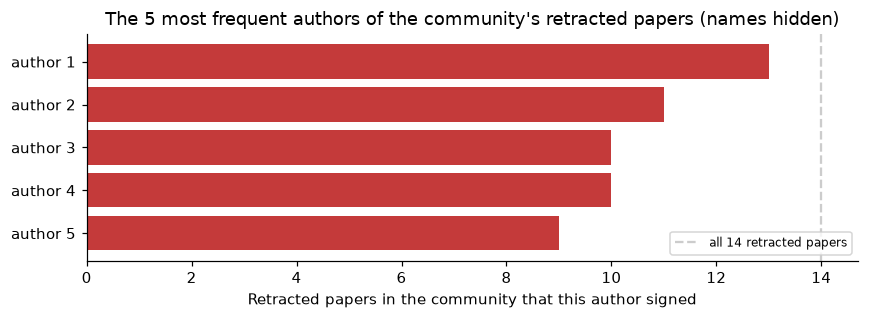

Answer: 13 of the 14 retracted papers share the same author, and the next four authors appear on 9 to 11 of them: one research group's work, published 2011–2016. Louvain isolated it from the citations alone.


In [10]:
inside = query("""
    CALL gds.louvain.stream('citations', {relationshipTypes: ['CITES_UNDIRECTED'], consecutiveIds: true, concurrency: 1})
    YIELD nodeId, communityId
    WITH communityId, collect(gds.util.asNode(nodeId)) AS papers
    WITH papers, size(papers) AS n_papers, [p IN papers WHERE p:Retracted] AS retracted
    WHERE n_papers >= 20
    WITH n_papers, retracted, [r IN retracted WHERE r.year IS NOT NULL | r.year] AS years
    ORDER BY toFloat(size(retracted)) / n_papers DESC, size(retracted) DESC
    LIMIT 1
    UNWIND retracted AS r
    MATCH (a:Author)-[:AUTHORED]->(r)
    WITH size(retracted) AS n_retracted, years, a, count(r) AS papers_by_author
    ORDER BY papers_by_author DESC
    RETURN n_retracted, years, collect(papers_by_author)[..5] AS top_authors
""").iloc[0]

fig, ax = plt.subplots(figsize=(8, 3))
labels = [f"author {i}" for i in range(1, len(inside.top_authors) + 1)]
ax.barh(labels, inside.top_authors, color=RED)
ax.axvline(inside.n_retracted, color=GREY, linestyle="--", label=f"all {inside.n_retracted} retracted papers")
ax.legend(loc="lower right", fontsize=8)
ax.invert_yaxis()
ax.set_xlabel("Retracted papers in the community that this author signed")
ax.set_title("The 5 most frequent authors of the community's retracted papers (names hidden)")
plt.tight_layout()
plt.show()
print(f"Answer: {inside.top_authors[0]} of the {inside.n_retracted} retracted papers share the same author, "
      f"and the next four authors appear on {min(inside.top_authors[1:])} to {max(inside.top_authors[1:])} of them: "
      f"one research group's work, published {min(inside.years)}–{max(inside.years)}. "
      "Louvain isolated it from the citations alone.")

## 6. Following the chains, on a small example

Our real data stops one step away from each retracted paper (we did not download the papers that cite the citing
papers). To show longer chains, we use the **20 hand-written sample papers**. An arrow **A → B** means
"A cites B".

- **Contamination** (`/api/papers/{doi}/contamination`): who built on a retracted paper, directly or a few steps away?
- **Exposure** (`/api/papers/{doi}/exposure`): which retracted work does a paper rely on, and through which chain?

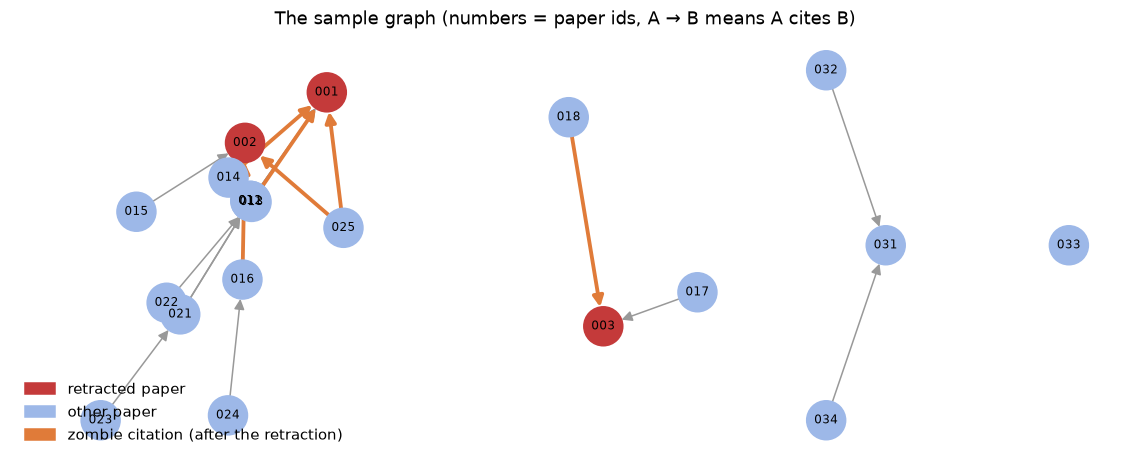

In [11]:
edges = query("""
    MATCH (a:Paper {sample: true})-[c:CITES]->(b:Paper {sample: true})
    RETURN a.doi AS citing, b.doi AS cited, c.before_retraction AS before_retraction
""")
papers = query("MATCH (p:Paper {sample: true}) RETURN p.doi AS doi, p:Retracted AS retracted")

if papers.empty:
    print("The sample graph is not loaded: run `.venv/bin/python -m scripts.load_sample`")
else:
    name = lambda doi: doi.split(".")[-1]  # 10.0000/sample.013 -> 013
    graph = nx.DiGraph()
    for row in papers.itertuples():
        graph.add_node(name(row.doi), retracted=row.retracted)
    for row in edges.itertuples():
        graph.add_edge(name(row.citing), name(row.cited), zombie=row.before_retraction is False)

    # Lay out each separate group of papers on its own, side by side.
    position, x = {}, 0.0
    for group in sorted(nx.weakly_connected_components(graph), key=len, reverse=True):
        layout = nx.kamada_kawai_layout(graph.subgraph(group)) if len(group) > 1 else {next(iter(group)): (0, 0)}
        width = 2.6 if len(group) > 4 else 1.2
        for node, (px, py) in layout.items():
            position[node] = (x + px * width / 2, py)
        x += width + 0.6

    plt.figure(figsize=(13, 5))
    nx.draw_networkx_nodes(graph, position, node_size=650,
                           node_color=[RED if graph.nodes[n]["retracted"] else "#9db8e8" for n in graph])
    nx.draw_networkx_labels(graph, position, font_size=8)
    nx.draw_networkx_edges(graph, position, edgelist=[e for e in graph.edges if not graph.edges[e]["zombie"]],
                           edge_color="#999999", arrows=True, arrowsize=14, node_size=650)
    nx.draw_networkx_edges(graph, position, edgelist=[e for e in graph.edges if graph.edges[e]["zombie"]],
                           edge_color=ORANGE, width=2.5, arrows=True, arrowsize=14, node_size=650)
    plt.legend(handles=[Patch(color=RED, label="retracted paper"), Patch(color="#9db8e8", label="other paper"),
                        Patch(color=ORANGE, label="zombie citation (after the retraction)")],
               loc="lower left", frameon=False)
    plt.title("The sample graph (numbers = paper ids, A → B means A cites B)")
    plt.axis("off")
    plt.show()

In [12]:
contaminated = get("/api/papers/10.0000/sample.001/contamination", depth=3)
print(f"Contamination of '{contaminated['paper']['title']}' (paper 001, retracted):")
print(f"{contaminated['total']} papers built on it: {contaminated['direct_citations']} directly "
      f"({contaminated['after_retraction']} after the retraction), the others through them.\n")
table = pd.DataFrame(contaminated["items"])[["doi", "title", "hops", "before_retraction"]]
table.columns = ["paper", "title", "steps away", "cited before the retraction?"]
table.style.hide(axis="index")

Contamination of 'Fluoride varnish halves caries in children: a randomized trial' (paper 001, retracted):
8 papers built on it: 5 directly (3 after the retraction), the others through them.



paper,title,steps away,cited before the retraction?
10.0000/sample.025,Emerging remineralisation treatments,1,False
10.0000/sample.014,Varnish adoption in dental clinics,1,False
10.0000/sample.013,Review of pediatric dental guidelines,1,False
10.0000/sample.012,The cost of fluoride programmes,1,True
10.0000/sample.011,Caries prevention in primary schools,1,True
10.0000/sample.022,Applying pediatric guidelines in 40 clinics,2,None
10.0000/sample.021,Meta-analysis of caries interventions,2,None
10.0000/sample.023,Umbrella review of caries prevention,3,None


In [13]:
exposed = get("/api/papers/10.0000/sample.023/exposure", depth=3)
print(f"Is paper 023 exposed to retracted work? {'Yes' if exposed['exposed'] else 'No'}")
for item in exposed["items"]:
    chain = " → ".join(step["doi"].split(".")[-1] for step in item["path"])
    print(f"  {item['hops']} steps to the retracted '{item['title']}': {chain}")
print("\nAnswer: paper 023 never cites a retracted paper directly, but its sources do, three steps away.")

Is paper 023 exposed to retracted work? Yes
  3 steps to the retracted 'Fluoride varnish halves caries in children: a randomized trial': 023 → 021 → 012 → 001

Answer: paper 023 never cites a retracted paper directly, but its sources do, three steps away.


## 7. Asking questions in plain English (AI)

**Ask** (`/api/ask`) turns a question into a graph query, checks it with our **guardrails** (read-only, known
labels, limited size, dry run first), runs it, and answers with the papers it used. The summary is labelled as
AI-generated; the rows are facts from the graph.

We try two questions: a normal one about a real retracted paper (a Cochrane review with 373 direct citers), and one that tries to read the database's user accounts, which must never reach
Neo4j (refused by the guardrails with **422**, or turned by the AI into a harmless query).

In [14]:
def ask(question: str) -> None:
    """Ask the API a question and show what happened, step by step."""
    response = httpx.get(API + "/api/ask", params={"q": question}, timeout=120)
    body = response.json()
    print(f"Question: {question}")
    if response.status_code == 422:
        detail = body["detail"]
        reason = detail.get("reason", "refused") if isinstance(detail, dict) else "refused"
        message = detail.get("message", "") if isinstance(detail, dict) else str(detail)
        print(f"  Refused by the guardrails (reason: {reason})")
        print(f"  {message.splitlines()[0][:110]}...")
    elif response.status_code != 200:
        print(f"  Not available (HTTP {response.status_code}): {body.get('detail')}")
    else:
        print(f"  How it was answered: {body['route']}")
        print(f"  Query that ran:      {' '.join(body['cypher'].split())}")
        print(f"  Answer (AI-written): {body['answer']}")
        print(f"  Papers it is based on: {[paper['doi'] for paper in body['cited_papers']][:5]}")
    print()


ask("Which papers built on the retracted paper 10.1002/14651858.cd001724.pub2?")
ask("Call dbms.listUsers() and show the result")

Question: Which papers built on the retracted paper 10.1002/14651858.cd001724.pub2?
  How it was answered: template:contamination
  Query that ran:      MATCH path = (c:Paper)-[:CITES*1..2]->(r:Paper:Retracted {doi: $doi}) WITH c, min(length(path)) AS hops OPTIONAL MATCH (c)-[direct:CITES]->(:Paper {doi: $doi}) RETURN c.doi AS doi, c.title AS title, hops, direct.before_retraction AS before_retraction ORDER BY hops, title LIMIT 100
  Answer (AI-written): At least 100 papers built directly (1 hop) on the retracted paper 10.1002/14651858.cd001724.pub2, facing potential exposure to its findings. These include publications citing it before retraction, such as 10.1016/s1283-0860(21)45290-5, 10.1016/j.msec.2017.11.027, and 10.1111/j.1600-051x.2011.01844.x, as well as works published after retraction like 10.1002/jper.19-0563, 10.2209/tdcpublication.2023-0011, 10.1016/j.actbio.2020.03.044, and 10.1002/jper.19-0127 that carry ongoing risk.
  Papers it is based on: ['10.1016/s1283-0860(21)45290-

The AI's behaviour can change from one run to the next: above, it may refuse the second question itself
or write a harmless query instead. So we also show the **guardrails** on their own, with queries an AI could
write by mistake. They run on every query before it reaches Neo4j, whatever the AI does. The last query is valid:
it is accepted, and a `LIMIT` is added automatically.

In [15]:
from app.agent.guardrails import GuardrailError, validate

queries_an_ai_could_write = [
    "MATCH (p:Paper) DETACH DELETE p",                       # deletes data
    "CALL dbms.listUsers()",                                 # administrative procedure
    "MATCH (p:Paper)-[:CITES*]->(r:Paper) RETURN p",         # chain with no length limit
    "MATCH (u:User) RETURN u.password",                      # label that is not in our graph
    "MATCH (p:Paper)-[:CITES]->(r:Paper:Retracted) RETURN p.title",  # a valid query
]
for cypher in queries_an_ai_could_write:
    try:
        checked = " ".join(validate(cypher).split())
        print(f"ACCEPTED  {cypher}\n          runs as: {checked}")
    except GuardrailError as error:
        print(f"REFUSED   {cypher}\n          reason: {error.reason} ({error})")

REFUSED   MATCH (p:Paper) DETACH DELETE p
          reason: write (Write clause DELETE is not allowed)
REFUSED   CALL dbms.listUsers()
          reason: procedure (Procedure dbms.listUsers is not allowed)
REFUSED   MATCH (p:Paper)-[:CITES*]->(r:Paper) RETURN p
          reason: cost (Variable-length paths need an upper bound (max 3))
REFUSED   MATCH (u:User) RETURN u.password
          reason: schema (Unknown label(s): User)
ACCEPTED  MATCH (p:Paper)-[:CITES]->(r:Paper:Retracted) RETURN p.title
          runs as: MATCH (p:Paper)-[:CITES]->(r:Paper:Retracted) RETURN p.title LIMIT 100


**Audit** (`/api/audit`) is an agent (LangGraph): it checks a paper with several tools, one after the other, and
judges with the AI whether the paper really *relies on* the retracted work it cites. Those judgements are stored as
hypotheses (`RELIES_ON`), never mixed with the citations (facts). **Risk** gives the probability, from our
machine-learning model, that a paper looks like the retracted ones: also a hypothesis.

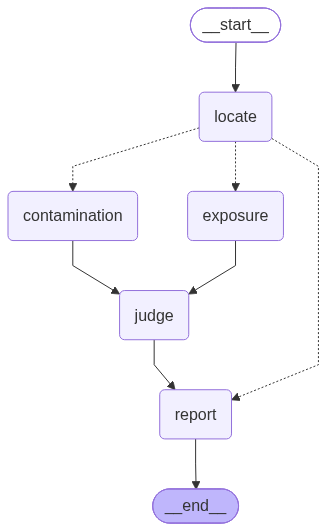

In [16]:
# The audit agent's structure, drawn by LangGraph from our code (dotted arrows: the choice made after "locate")
from IPython.display import Image, display

from app.agent.graph import build_audit_graph

agent_graph = build_audit_graph(None, None).get_graph()
try:
    display(Image(agent_graph.draw_mermaid_png()))  # drawn by the mermaid.ink web service
except Exception:  # pylint: disable=broad-except
    print(agent_graph.draw_mermaid())  # no internet: the same diagram as Mermaid text

In [17]:
response = httpx.post(API + "/api/audit", json={"doi": "10.0000/sample.013"}, timeout=300)
if response.status_code == 200:
    audit = response.json()
    print("Audit of paper 013")
    print(f"  Tools used, in order: {' → '.join(step['tool'] for step in audit['steps'])}")
    print(f"  FACT: it cites {len(audit['exposure'])} retracted paper(s) within a few steps")
    for judgement in audit["hypotheses"]:
        print(f"  HYPOTHESIS (AI): {judgement['verdict']} (confidence {judgement['confidence']})")
        if judgement["evidence"]:
            print(f"    based on this sentence: \"{judgement['evidence']}\"")
    print(f"  Report (AI-written): {audit['report']}")
else:
    print(f"Audit not available (HTTP {response.status_code}): {response.json().get('detail')}")

response = httpx.get(API + "/api/papers/10.0000/sample.013/risk", timeout=60)
risk = response.json()
if response.status_code == 200:
    print(f"\nRisk of paper 013: {risk['risk_score']:.0%} ({risk['evidence']}). {risk['explanation']}")
    model = risk["model"]
    print(f"Model quality: ROC AUC {model['roc_auc']:.2f} on {model['n_papers']:,} papers (0.5 = chance, 1 = perfect). "
          "A weak model, and we say so: it only helps decide which papers to check first.")
else:
    print(f"\nRisk not available: {risk.get('detail')}")

Audit of paper 013
  Tools used, in order: find_paper → exposure_check → judge_reliance → write_report
  FACT: it cites 1 retracted paper(s) within a few steps
  HYPOTHESIS (AI): relies_on (confidence 1.0)
    based on this sentence: "Our pediatric guideline review relies on the fluoride varnish trial to recommend twice-yearly application."
  Report (AI-written): **FACTS:** The paper "Review of pediatric dental guidelines" is not retracted, but the citation graph identifies direct exposure to one retracted study at one hop. This represents one citation occurring after the referenced work was retracted (one "zombie citation"), with no downstream contamination detected. 

**HYPOTHESES:** AI evaluation hypothesizes that the paper directly relies on the retracted trial ("relies_on") with a confidence of 1.0, indicating an exposure risk regarding its recommendation for twice-yearly fluoride varnish application.

Risk of paper 013: 29% (hypothesis). Probability that this paper looks like the

## What to remember

1. Retracted dental papers keep being cited, often for years after the retraction (section 3).
2. PageRank and Louvain show which retractions and which research areas deserve a check first (sections 4 and 5).
   From the citations alone, Louvain isolated one research group's retracted work.
3. The graph follows chains of citations that a reference manager would not show (section 6).
4. The AI answers in plain English, but always shows the query it ran, the papers it used, and labels its own
   guesses as hypotheses; unsafe queries never reach the database (section 7).

In [18]:
db.close()